# EN4554 Assignment 2
## Dissanayake D.M.A.D | 220134K

**GitHub repository:** https://github.com/AkilaDissanayake/EN4554_Assignment_2.git

**First Setup the Configurations for the notebook**

In [ ]:
import os, sys, json, math, time, random, copy, warnings
from collections import defaultdict  # To save training history

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

# ---------------- configuration ----------------
# True: 1 epoch on 2k images per experiment (to check everything runs)
QUICK_TEST = False
USE_DRIVE = True    # True: keep the dataset and all results in Google Drive
SEED = 42           # To get repeatable results

# Check whether in colab or not to decide where to save
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/EN4554_A2'
elif IN_COLAB:
    BASE_DIR = '/content'
else:
    BASE_DIR = '.'  # Current directory
DATA_DIR = os.path.join(BASE_DIR, 'data')  # CIFAR-10 is stored here
# Saved training runs
RESULTS_DIR = os.path.join(BASE_DIR, 'results_quick' if QUICK_TEST else 'results')
# Create the directories
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---------------- reproducibility ----------------
def set_seed(seed=SEED):
    """Seed every random number generator used in the notebook."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
# False: cuDNN does not search for the fastest algorithm, so reruns repeat more closely
torch.backends.cudnn.benchmark = False

# ---------------- device ----------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# fp16 mixed precision for the CNNs, only on the GPU
# (T4 is 16 bit but for loss we can keep 32 bits)
USE_AMP = device.type == 'cuda'

def n_epochs(n):
    """Epochs for an experiment: n normally, 1 in quick-test mode."""
    return 1 if QUICK_TEST else n

# With fp16 the gradient scaler may skip the very first optimizer steps (overflow while
# it calibrates); PyTorch then warns that the LR scheduler stepped before the optimizer.
# That is harmless here.
warnings.filterwarnings('ignore', message='Detected call of `lr_scheduler.step')
# Higher res plots, faint grid
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

# Print out the configuration
gpu_name = f' ({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else ''
print(f'torch {torch.__version__} | device: {device}{gpu_name}')
print(f'dataset folder: {DATA_DIR}')
print(f'results folder: {RESULTS_DIR}')

Mounted at /content/drive
torch 2.11.0+cu130 | device: cuda (Tesla T4)
dataset folder: /content/drive/MyDrive/EN4554_A2/data
results folder: /content/drive/MyDrive/EN4554_A2/results


**Second step**

- Download the dataset to the drive.
- The 50,000 official training images are shuffled with a fixed seed and split into **45,000 training** and **5,000 validation** images.
- The per-channel **mean and standard deviation are computed on the 45k training images only**. The same values normalize the training, validation and test images. (Computing them on validation or test images would leak information about those images.)
- Hyperparameters are chosen on the validation set only, and the test set is used once, at the very end (Task 4).

In [ ]:
CLASSES = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')  # Classes in CIFAR-10

# Downloads and extracts CIFAR-10 into DATA_DIR on the first run;
# afterwards the files are only verified.
train_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
test_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)

# Once extracted, the 170 MB archive is not needed any more;
# delete it to save Drive space.
archive = os.path.join(DATA_DIR, 'cifar-10-python.tar.gz')
if os.path.exists(archive):
    os.remove(archive)

# Convert data in to what PyTorch expects in memory
def to_uint8_tensor(dataset):
    """CIFAR-10 images as a (N, 3, 32, 32) uint8 tensor
    (torchvision stores them as N x 32 x 32 x 3)."""
    # Contiguous to rearrange the data in memory
    return torch.from_numpy(dataset.data).permute(0, 3, 1, 2).contiguous()

X_all, Y_all = to_uint8_tensor(train_raw), torch.tensor(train_raw.targets)
X_test, Y_test = to_uint8_tensor(test_raw), torch.tensor(test_raw.targets)

# 45k / 5k split with a fixed random permutation (list of shuffled integers)
perm = torch.randperm(len(Y_all), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45000], perm[45000:]  # First 45K is train, rest is val
# Make the training and validation sets with the selected indexes
X_train, Y_train = X_all[train_idx], Y_all[train_idx]
X_val, Y_val = X_all[val_idx], Y_all[val_idx]

# Print out new shapes
print(f'training set:    X {tuple(X_train.shape)}, Y {tuple(Y_train.shape)}')
print(f'one sample:      X {tuple(X_train[0].shape)}, '
      f'Y = {Y_train[0].item()} ({CLASSES[Y_train[0]]})')

# Per-channel statistics from the 45k training images only
# (pixel values scaled to [0, 1])
MEAN = torch.stack([X_train[:, c].double().mean() for c in range(3)]).float() / 255
STD = torch.stack([X_train[:, c].double().std() for c in range(3)]).float() / 255
print('training mean per channel:', MEAN.numpy().round(4),
      '| std:', STD.numpy().round(4))

# To subtract the whole batch at once, reshape to (1, 3, 1, 1) and move it to the GPU
MEAN_GPU, STD_GPU = MEAN.view(1, 3, 1, 1).to(device), STD.view(1, 3, 1, 1).to(device)

def normalize(x_uint8):
    """uint8 images -> float images with zero mean and unit variance per channel."""
    return (x_uint8.float() / 255 - MEAN_GPU) / STD_GPU

class Split:
    """One data split (train / val / test) stored on the device
    as uint8 images and integer labels."""

    def __init__(self, x, y):
        self.x, self.y = x.to(device), y.to(device)

    def __len__(self):
        return len(self.y)

    def subset(self, n, seed=SEED):
        """A random subset of n images (fixed by the seed)."""
        gen = torch.Generator().manual_seed(seed)
        idx = torch.randperm(len(self), generator=gen)[:n].to(device)
        return Split(self.x[idx], self.y[idx])

    def batches(self, batch_size, shuffle=False, augment=None, gen=None):
        """Yield (normalized images, labels) mini-batches.
        shuffle: random order (drawn from the generator `gen`),
        augment: optional function applied to each batch."""
        if shuffle:
            order = torch.randperm(len(self), device=device, generator=gen)
        else:
            order = torch.arange(len(self), device=device)
        for start in range(0, len(self), batch_size):
            idx = order[start:start + batch_size]
            xb = normalize(self.x[idx])
            if augment is not None:
                xb = augment(xb, gen)
            yield xb, self.y[idx]

train_set, val_set = Split(X_train, Y_train), Split(X_val, Y_val)
test_set = Split(X_test, Y_test)
if QUICK_TEST:
    train_set, val_set = train_set.subset(2048), val_set.subset(1024)
print(f'train: {len(train_set)} | validation: {len(val_set)} '
      f'| test: {len(test_set)} images')

training set:    X (45000, 3, 32, 32), Y (45000,)
one sample:      X (3, 32, 32), Y = 6 (frog)
training mean per channel: [0.4917 0.4823 0.4467] | std: [0.2471 0.2435 0.2616]
train: 45000 | validation: 5000 | test: 10000 images


## Data augmentation for task 3


- **Flip & crop:** flip each image horizontally with probability 0.5, pad it by 4 pixels on every side, and cut out a random 32×32 window. Padding happens after normalization, so the border is the mean colour (value 0).
- **Cutout** (DeVries & Taylor, 2017): set one random `size × size` square of each image to 0, the mean colour. The square's centre can be anywhere in the image, so the square may be partly outside it. The network then cannot rely on a single small region of the object.
- **Mixup** (Zhang et al., 2018): blend each image with another random image of the batch, $\tilde x = \lambda x_i + (1-\lambda)x_j$ with $\lambda\sim\mathrm{Beta}(\alpha,\alpha)$. The loss is blended the same way, $\lambda\,\mathrm{CE}(y_i) + (1-\lambda)\,\mathrm{CE}(y_j)$. Mixup needs the labels, so it is applied inside the training loop below instead of here.

In [ ]:
def random_flip_crop(x, gen, pad=4):
    """Random horizontal flip + random 32x32 crop
    from the image padded by `pad` pixels."""
    B, C, H, W = x.shape
    # Flip: choose for every image whether to mirror it
    flip = torch.rand(B, device=x.device, generator=gen) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    # Crop: pad, then pick a random top-left corner (dy, dx) in [0, 2*pad]
    # for every image
    x_pad = F.pad(x, (pad, pad, pad, pad))
    dy = torch.randint(0, 2 * pad + 1, (B,), device=x.device, generator=gen)
    dx = torch.randint(0, 2 * pad + 1, (B,), device=x.device, generator=gen)
    # (B,1,H,1)
    rows = (dy[:, None] + torch.arange(H, device=x.device))[:, None, :, None]
    # (B,1,1,W)
    cols = (dx[:, None] + torch.arange(W, device=x.device))[:, None, None, :]
    b = torch.arange(B, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    return x_pad[b, c, rows, cols]  # Gathers a different window from every image

def random_cutout(x, gen, size=16):
    """Set one random size x size square per image to 0
    (= the mean colour after normalization)."""
    B, _, H, W = x.shape
    # Square centres
    cy = torch.randint(0, H, (B, 1, 1), device=x.device, generator=gen)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device, generator=gen)
    ys = torch.arange(H, device=x.device)[None, :, None]
    xs = torch.arange(W, device=x.device)[None, None, :]
    # (B, H, W) mask of the square
    inside = ((ys >= cy - size // 2) & (ys < cy + size // 2) &
              (xs >= cx - size // 2) & (xs < cx + size // 2))
    return x * (~inside)[:, None].to(x.dtype)

def make_augment(flip_crop=False, cutout=0):
    """Combine the chosen augmentations into one function
    (None if there is no augmentation)."""
    if not flip_crop and not cutout:
        return None
    def augment(x, gen):
        if flip_crop:
            x = random_flip_crop(x, gen)
        if cutout:
            x = random_cutout(x, gen, cutout)
        return x
    return augment

## Shared training code
Tasks 2(c), 3 and 4 train CNNs with PyTorch's autograd (`loss.backward()`) and share these helpers:

- `train_model(...)`: the training loop. Every epoch it shuffles the training split and applies the requested augmentation and mixup. It takes one optimizer step per mini-batch and steps the learning-rate schedule after every iteration. At the end of the epoch it records the training loss and the validation loss and accuracy. It returns these histories as a dictionary of lists.
- `evaluate(model, split)`: average loss and accuracy in eval mode.
- `warmup_cosine(...)`: the learning-rate schedule. The learning rate rises linearly during the warm-up, then follows a cosine down to zero. (To stop too large steps at first)
- `cached(name, fn)`: runs the experiment `fn()` once and saves its result, and optionally the model weights, in `RESULTS_DIR`. If the file already exists, it is loaded instead of training again.

In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

def steps_per_epoch(data, batch_size):
    return math.ceil(len(data) / batch_size)

def warmup_cosine(optimizer, total_steps, warmup_steps=0):
    """Per-iteration learning-rate schedule: linear warm-up, then cosine decay to 0."""
    def factor(step):  # Multiplies the optimizer's base learning rate
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(progress, 1.0)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)

@torch.no_grad()
def evaluate(model, data, batch_size=1000):
    """Average cross-entropy loss and accuracy of `model` on a Split, in eval mode."""
    model.eval()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    for xb, yb in data.batches(batch_size):
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(xb)
        loss_sum += F.cross_entropy(out.float(), yb, reduction='sum')
        correct += (out.argmax(1) == yb).sum()
    return loss_sum.item() / len(data), correct.item() / len(data)

def train_model(model, optimizer, train, val, epochs, scheduler=None, batch_size=128,
                augment=None, mixup_alpha=0.0, label_smoothing=0.0, train_eval=None,
                seed=SEED, name='', log_every=5):
    """Train `model` and return its history: per-iteration loss, per-epoch train loss,
    val loss / accuracy, ...

    augment:     function applied to every training batch (see make_augment)
    mixup_alpha: > 0 enables mixup with lambda ~ Beta(alpha, alpha)
    train_eval:  optional clean split, evaluated each epoch in eval mode,
                 used as the 'train accuracy'
    """
    model.to(device)
    # Shuffling / augmentation randomness of this run
    gen = torch.Generator(device=device)
    gen.manual_seed(seed)
    rng = np.random.default_rng(seed)     # Mixup lambdas
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)  # Loss scaling for fp16
    hist = defaultdict(list)
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        for xb, yb in train.batches(batch_size, shuffle=True, augment=augment, gen=gen):
            if mixup_alpha > 0:
                lam = float(rng.beta(mixup_alpha, mixup_alpha))
                partner = torch.randperm(len(yb), device=device, generator=gen)
                xb = lam * xb + (1 - lam) * xb[partner]

            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
                if mixup_alpha > 0:
                    loss = lam * loss + (1 - lam) * F.cross_entropy(
                        out, yb[partner], label_smoothing=label_smoothing)

            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            # Unscales the gradients, then calls optimizer.step()
            scaler.step(optimizer)
            scaler.update()
            if scheduler is not None:
                scheduler.step()
            # Kept on the GPU; copied to the CPU once per epoch
            losses.append(loss.detach())

        # ---- end of epoch: record the history ----
        iter_loss = torch.stack(losses).float().cpu()
        hist['iter_loss'] += iter_loss.tolist()
        hist['train_loss'].append(iter_loss.mean().item())
        val_loss, val_acc = evaluate(model, val)
        hist['val_loss'].append(val_loss)
        hist['val_acc'].append(val_acc)
        if train_eval is not None:
            _, train_acc = evaluate(model, train_eval)
            hist['train_eval_acc'].append(train_acc)
        hist['lr'].append(optimizer.param_groups[0]['lr'])

        diverged = (not math.isfinite(hist['train_loss'][-1])
                    or hist['train_loss'][-1] > 1e3)
        if log_every and (epoch % log_every == 0 or epoch == epochs or diverged):
            extra = (f" | train acc {hist['train_eval_acc'][-1]:.3f}"
                     if train_eval is not None else '')
            print(f"[{name}] ep {epoch:2d} | loss {hist['train_loss'][-1]:.3f} "
                  f"| val loss {val_loss:.3f} | val acc {val_acc:.3f}{extra}")
        if diverged:
            print(f'[{name}] diverged at epoch {epoch}; stopping this run')
            hist['diverged'] = True
            break

    hist['time'] = time.time() - start
    return dict(hist)

def cached(name, fn, model=None):
    """Run the experiment fn() once and save its result (and the weights of `model`)
    in RESULTS_DIR. If the result already exists, load it instead of retraining."""
    result_path = os.path.join(RESULTS_DIR, f'{name}.json')
    weights_path = os.path.join(RESULTS_DIR, f'{name}.pt')
    if os.path.exists(result_path) and (model is None or os.path.exists(weights_path)):
        if model is not None:
            model.load_state_dict(torch.load(weights_path, map_location=device))
        print(f'[{name}] loaded saved result')
        with open(result_path) as f:
            return json.load(f)
    result = fn()
    with open(result_path, 'w') as f:
        json.dump(result, f)
    if model is not None:
        torch.save(model.state_dict(), weights_path)
    return result

### Check of the data pipeline
After normalization, every channel of the training data should have mean ≈ 0 and standard deviation ≈ 1. The figure applies each augmentation to the same eight training images, one augmentation per row.

normalized training data | mean: [0. 0. 0.] | std: [1. 1. 1.]


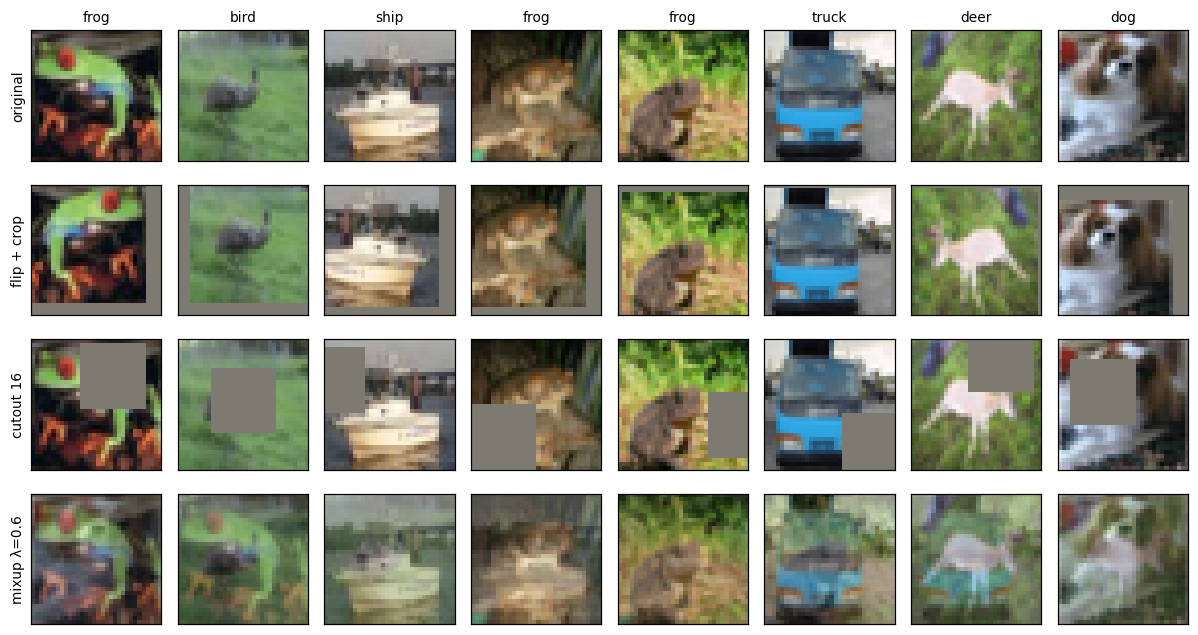

In [ ]:
# Mean and std per channel over all normalized training images
total = torch.zeros(3, device=device)
total_sq = torch.zeros(3, device=device)
count = 0
for xb, _ in train_set.batches(5000):
    total += xb.sum(dim=(0, 2, 3))
    total_sq += (xb ** 2).sum(dim=(0, 2, 3))
    count += xb.numel() // 3
mean = total / count
std = (total_sq / count - mean ** 2).sqrt()
print('normalized training data | mean:', mean.cpu().numpy().round(4),
      '| std:', std.cpu().numpy().round(4))

# The augmentations on eight training images
gen = torch.Generator(device=device)
gen.manual_seed(0)
xb, yb = next(train_set.batches(8))
rows = {'original': xb,
        'flip + crop': random_flip_crop(xb, gen),
        'cutout 16': random_cutout(xb, gen),
        'mixup λ=0.6': 0.6 * xb + 0.4 * xb.roll(1, dims=0)}

fig, axes = plt.subplots(len(rows), 8, figsize=(11, 6))
for r, (title, images) in enumerate(rows.items()):
    # Remove the normalization for display
    images = (images * STD_GPU + MEAN_GPU).clamp(0, 1).cpu()
    for c in range(8):
        ax = axes[r, c]
        ax.imshow(images[c].permute(1, 2, 0))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if c == 0:
            ax.set_ylabel(title, fontsize=9)
        if r == 0:
            ax.set_title(CLASSES[yb[c]], fontsize=9)
plt.tight_layout()
plt.show()

---
## Task 1: Backpropagation

### (a) Layers with explicit forward and backward passes
**Back-propagation** computes the gradients from the output layer back to the input layer, using the chain rule. Each layer saves what it needs during `forward`. Its `backward` receives the upstream gradient $G = \partial L/\partial Y$ and returns the downstream gradient for its input: downstream gradient = local gradient × upstream gradient.

**Linear**

- Forward: $Y = XW^\top + b$
- Backward: $\dfrac{\partial L}{\partial W} = G^\top X, \qquad \dfrac{\partial L}{\partial b} = \sum_n G_n, \qquad \dfrac{\partial L}{\partial X} = G\,W$

**ReLU**

- Forward: $Y = \max(0, X)$
- Backward: $\dfrac{\partial L}{\partial X} = G \odot \mathbf{1}[X > 0]$

**Sigmoid**

- Forward: $Y = \sigma(X) = \dfrac{1}{1 + e^{-X}}$
- Backward: $\dfrac{\partial L}{\partial X} = G \odot Y \odot (1 - Y)$

**Softmax cross-entropy** (scores $s = f(x_i; W)$, true class $y_i$, batch of $N$ images)

- Forward: $P(Y=k \mid X=x_i) = \dfrac{\exp(s_k)}{\sum_j \exp(s_j)}$
- Loss: $L_i = -\log P(Y=y_i \mid X=x_i)$ and $L = \dfrac{1}{N}\sum_{i=1}^{N} L_i$
- Backward: $\dfrac{\partial L}{\partial s_k} = \dfrac{1}{N}\big(P(Y=k \mid X=x_i) - \mathbf{1}[k = y_i]\big)$

**Numerical stability.** The softmax subtracts each row's largest score before exponentiating, so `exp` can never overflow. This does not change the probabilities.

**Initialization.** The weights use Kaiming (He) initialization, $W \sim \mathcal{N}(0,\ 2/n_{\text{in}})$, where $n_{\text{in}}$ is the number of inputs of the layer.

In [ ]:
class Linear:
    """Fully connected layer y = x W^T + b with a manual backward pass."""

    def __init__(self, in_features, out_features, gen=None,
                 dtype=torch.float32, device=device):
        std = math.sqrt(2.0 / in_features)  # Kaiming (He) init: Var(W) = 2 / n_in
        W = torch.randn(out_features, in_features, generator=gen, dtype=torch.float64)
        self.W = (W * std).to(device, dtype)
        # Biases start at 0
        self.b = torch.zeros(out_features, dtype=dtype, device=device)
        self.dW = self.db = None  # Gradients, filled by backward()

    def forward(self, x):
        self.x = x                      # Save the input, needed for dL/dW
        return x @ self.W.T + self.b

    def backward(self, grad_out):
        self.dW = grad_out.T @ self.x   # dL/dW = G^T X
        self.db = grad_out.sum(dim=0)   # dL/db = sum of G over the batch
        return grad_out @ self.W        # dL/dX = G W, passed to the previous layer

class ReLU:
    def forward(self, x):
        # True where the derivative is 1, False where it is 0
        self.mask = x > 0
        return x * self.mask

    def backward(self, grad_out):
        return grad_out * self.mask     # Gradient only flows through the active units

class Sigmoid:
    def forward(self, x):
        self.y = 1.0 / (1.0 + torch.exp(-x))
        return self.y                   # Output is saved for the backward pass

    def backward(self, grad_out):
        return grad_out * self.y * (1.0 - self.y)  # sigma'(x) = sigma(x) (1 - sigma(x))

class SoftmaxCrossEntropy:
    """Mean cross-entropy of softmax(logits); backward returns dL/dlogits."""

    def forward(self, logits, y):
        # Subtract the row max so exp() cannot overflow
        z = logits - logits.max(dim=1, keepdim=True).values
        log_p = z - z.exp().sum(dim=1, keepdim=True).log()   # log softmax
        self.p, self.y = log_p.exp(), y  # Save probabilities and labels for backward
        # Mean of -log p(correct class)
        return -log_p[torch.arange(len(y), device=y.device), y].mean()

    def backward(self):
        grad = self.p.clone()
        rows = torch.arange(len(self.y), device=self.y.device)
        grad[rows, self.y] -= 1.0       # softmax - onehot
        return grad / len(self.y)       # Divide by N (mean loss)

class MLP:
    """Multi-layer perceptron built from the layers above."""

    def __init__(self, sizes, activation='relu', seed=SEED,
                 dtype=torch.float32, device=device):
        # Own generator so the initial weights repeat
        gen = torch.Generator().manual_seed(seed)
        self.layers = []
        for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(n_in, n_out, gen, dtype, device))
            if i < len(sizes) - 2:      # No activation after the output layer
                self.layers.append(ReLU() if activation == 'relu' else Sigmoid())
        self.criterion = SoftmaxCrossEntropy()

    @property
    def linears(self):
        # Only the layers with weights
        return [layer for layer in self.layers if isinstance(layer, Linear)]

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x                        # Logits

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):
        """Backpropagate from the loss through all layers.
        Fills dW, db of every Linear layer and returns dL/dx."""
        grad = self.criterion.backward()
        for layer in reversed(self.layers):  # From the output back to the input
            grad = layer.backward(grad)
        return grad

    def parameters(self):
        # [W1, b1, W2, ...]
        return [t for layer in self.linears for t in (layer.W, layer.b)]

    def grads(self):
        return [t for layer in self.linears for t in (layer.dW, layer.db)]  # Same order

    def sgd_step(self, lr):
        for layer in self.linears:      # Plain SGD: theta = theta - lr * gradient
            layer.W -= lr * layer.dW
            layer.b -= lr * layer.db

### MLP architecture and data flow
The MLP is a stack of the layers above. Every `Linear` layer except the last is followed by an activation (ReLU, or sigmoid in Task 1(d)), and the last `Linear` layer outputs the 10 class scores (logits).

```text
forward:   x (N, 3072) → Linear 1 → act → … → Linear L → logits (N, 10) → SoftmaxCE → loss
backward:  dL/dx ← Linear 1 ← act ← … ← Linear L ← dL/dlogits ← SoftmaxCE
```

- **Forward (`MLP.loss`):** each layer saves what its backward pass needs: `Linear` its input $X$, `ReLU` the mask $X > 0$, `Sigmoid` its output $Y$, and `SoftmaxCrossEntropy` the probabilities and the labels.
- **Backward (`MLP.backward`):** starts from $\partial L/\partial\,\text{logits} = (P - \text{onehot})/N$ and visits the layers in reverse order. Each layer turns the upstream gradient into the downstream gradient; every `Linear` layer also stores its gradients $\partial L/\partial W$ and $\partial L/\partial b$ for the update.
- **Update (`MLP.sgd_step`):** $W \leftarrow W - \eta\,\partial L/\partial W$ and $b \leftarrow b - \eta\,\partial L/\partial b$ for every `Linear` layer.

### (b) Gradient check
Gradients are compared with:

1. **Autograd:** the same network rebuilt with `requires_grad=True` tensors and `F.cross_entropy`.
2. **Centred finite differences:** $\dfrac{\partial L}{\partial\theta_i}\approx\dfrac{L(\theta+h e_i)-L(\theta-h e_i)}{2h}$ with $h=10^{-6}$, for every weight, bias and input entry.

**Relative error** $= \|g_{\text{ours}}-g_{\text{ref}}\|_2 \,/\, (\|g_{\text{ours}}\|_2+\|g_{\text{ref}}\|_2)$, and `torch.allclose` (default tolerances) checks the match.

In [ ]:
def rel_error(a, b):
    # ||a - b|| / (||a|| + ||b||)
    return ((a - b).norm() / max((a.norm() + b.norm()).item(), 1e-12)).item()

def autograd_grads(mlp, x, y, activation):
    """Gradients of the same network computed by PyTorch autograd (reference)."""
    # Copies of the weights that autograd can track
    params = [p.detach().clone().requires_grad_(True) for p in mlp.parameters()]
    x_ref = x.detach().clone().requires_grad_(True)
    h = x_ref
    for i in range(0, len(params), 2):  # params = [W1, b1, W2, b2, ...]
        h = h @ params[i].T + params[i + 1]
        if i < len(params) - 2:         # Activation on every layer except the last
            h = torch.relu(h) if activation == 'relu' else torch.sigmoid(h)
    F.cross_entropy(h, y).backward()    # Autograd fills .grad
    return [p.grad for p in params], x_ref.grad

def finite_diff_grad(loss_fn, t, h=1e-6):
    """Centred finite-difference gradient of loss_fn() w.r.t. every entry of tensor t
    (t is modified in place and restored)."""
    grad = torch.zeros_like(t)
    flat, grad_flat = t.view(-1), grad.view(-1)
    for i in range(flat.numel()):
        original = flat[i].item()
        flat[i] = original + h
        loss_plus = loss_fn()           # L(theta + h)
        flat[i] = original - h
        loss_minus = loss_fn()          # L(theta - h)
        flat[i] = original              # Restore the value
        grad_flat[i] = (loss_plus - loss_minus) / (2 * h)
    return grad

rows = []
for activation in ['relu', 'sigmoid']:
    torch.manual_seed(SEED)
    # Small float64 network
    mlp = MLP([20, 16, 16, 10], activation=activation,
              dtype=torch.float64, device='cpu')
    x = torch.randn(8, 20, dtype=torch.float64)  # Batch of 8 random inputs
    y = torch.randint(0, 10, (8,))                # Random labels

    # Manual gradients
    mlp.loss(x, y)
    dx = mlp.backward()
    ours = [g.clone() for g in mlp.grads()] + [dx]
    # Autograd gradients
    ref_params, ref_x = autograd_grads(mlp, x, y, activation)
    autograd = ref_params + [ref_x]
    # Finite-difference gradients
    finite_diff = [finite_diff_grad(lambda: mlp.loss(x, y).item(), t)
                   for t in mlp.parameters() + [x]]

    names = [f'{k}{i + 1}' for i in range(len(mlp.linears)) for k in ('W', 'b')]
    names += ['x (input)']
    for name, g, a, d in zip(names, ours, autograd, finite_diff):
        rows.append({'activation': activation, 'tensor': name,
                     'rel. error vs autograd': rel_error(g, a),
                     'allclose (autograd)': torch.allclose(g, a),
                     'rel. error vs finite diff.': rel_error(g, d),
                     'allclose (finite diff.)': torch.allclose(g, d)})

# Table: one row per tensor, the ReLU and sigmoid networks side by side
grad_check = pd.DataFrame(rows)
error_columns = ['rel. error vs autograd', 'rel. error vs finite diff.']
errors = grad_check.pivot(index='tensor', columns='activation', values=error_columns)
display(errors.reindex(names).style.format('{:.2e}'))
checks = grad_check[['allclose (autograd)', 'allclose (finite diff.)']]
print(f'torch.allclose passed: {int(checks.values.sum())} of {checks.size} checks')

torch.allclose passed: 28 of 28 checks


**Interpretation:** All 28 `torch.allclose` checks passed, for both networks and for the input gradient.

- Compared with autograd, the relative errors are about $10^{-17}$ to $10^{-16}$ (at most $1.6\times10^{-16}$). This is the precision limit of float64, so the manual gradients are the same as autograd's.
- Compared with finite differences, the errors are about $10^{-10}$ to $10^{-8}$ (at most $1.1\times10^{-8}$). Finite differences are approximations, so a small error is expected.

### (c) Training the MLP with SGD
**Network:** 3072 → 512 → 256 → 10 with ReLU and Kaiming init, about 1.7M parameters. The hidden sizes are a design choice; the assignment does not fix them. Each normalized image is flattened into a vector of 3,072 values.

**Training:** plain mini-batch SGD with the manual backward pass. Learning rate 0.05, batch size 128, 20 epochs.

[t1c_mlp] loaded saved result


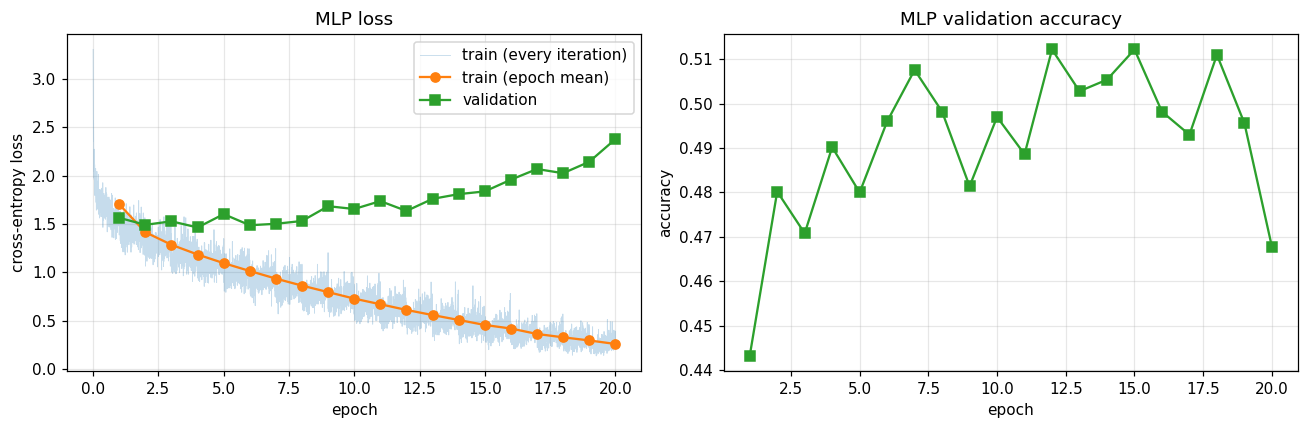

final validation accuracy: 0.4678 | best: 0.5122 (epoch 12)
train loss: 1.70 (epoch 1) -> 0.26 (epoch 20) | lowest val loss: 1.46 (epoch 4)
first-iteration loss: 3.30 (uniform guessing over 10 classes gives log(10) = 2.30)


In [ ]:
def evaluate_mlp(mlp, data, batch_size=1000):
    """Average loss and accuracy of the manual MLP on a Split."""
    loss_sum, correct = 0.0, 0
    for xb, yb in data.batches(batch_size):
        logits = mlp.forward(xb.flatten(1))
        # Mean loss x batch size = summed loss
        loss_sum += mlp.criterion.forward(logits, yb).item() * len(yb)
        # Predicted class = largest logit
        correct += (logits.argmax(1) == yb).sum().item()
    return loss_sum / len(data), correct / len(data)

def train_mlp(lr=0.05, epochs=20, batch_size=128):
    mlp = MLP([3072, 512, 256, 10], activation='relu')
    gen = torch.Generator(device=device)
    gen.manual_seed(SEED)                               # Same shuffling order every run
    hist = defaultdict(list)
    for epoch in range(1, epochs + 1):
        losses = []
        for xb, yb in train_set.batches(batch_size, shuffle=True, gen=gen):
            losses.append(mlp.loss(xb.flatten(1), yb))  # Forward
            mlp.backward()                              # Manual backward
            mlp.sgd_step(lr)                            # Manual SGD update
        losses = torch.stack(losses).cpu()
        hist['iter_loss'] += losses.tolist()            # Loss of every iteration
        hist['train_loss'].append(losses.mean().item()) # Mean loss of the epoch
        val_loss, val_acc = evaluate_mlp(mlp, val_set)
        hist['val_loss'].append(val_loss)
        hist['val_acc'].append(val_acc)
        if epoch == 1 or epoch % 5 == 0:
            print(f'epoch {epoch:2d} | train loss {hist["train_loss"][-1]:.4f} '
                  f'| val loss {val_loss:.4f} | val acc {val_acc:.4f}')
    return dict(hist)

# Train once, then load from Drive
mlp_hist = cached('t1c_mlp', lambda: train_mlp(epochs=n_epochs(20)))

# Plot the loss and the validation accuracy
iters_per_epoch = len(mlp_hist['iter_loss']) / len(mlp_hist['train_loss'])
epochs = np.arange(1, len(mlp_hist['train_loss']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(np.arange(len(mlp_hist['iter_loss'])) / iters_per_epoch, mlp_hist['iter_loss'],
         alpha=0.25, lw=0.6, label='train (every iteration)')
ax1.plot(epochs, mlp_hist['train_loss'], 'o-', label='train (epoch mean)')
ax1.plot(epochs, mlp_hist['val_loss'], 's-', label='validation')
ax1.set_xlabel('epoch'); ax1.set_ylabel('cross-entropy loss')
ax1.set_title('MLP loss'); ax1.legend()
ax2.plot(epochs, mlp_hist['val_acc'], 's-', color='C2')
ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy')
ax2.set_title('MLP validation accuracy')
plt.tight_layout()
plt.show()
best_epoch = int(np.argmax(mlp_hist['val_acc'])) + 1
print(f"final validation accuracy: {mlp_hist['val_acc'][-1]:.4f} "
      f"| best: {max(mlp_hist['val_acc']):.4f} (epoch {best_epoch})")
n_ep = len(mlp_hist['train_loss'])
low_epoch = int(np.argmin(mlp_hist['val_loss'])) + 1
print(f"train loss: {mlp_hist['train_loss'][0]:.2f} (epoch 1) -> "
      f"{mlp_hist['train_loss'][-1]:.2f} (epoch {n_ep}) | "
      f"lowest val loss: {min(mlp_hist['val_loss']):.2f} (epoch {low_epoch})")
print(f"first-iteration loss: {mlp_hist['iter_loss'][0]:.2f} "
      f"(uniform guessing over 10 classes gives log(10) = {math.log(10):.2f})")

**Interpretation:**

- The first loss is 3.30. Random guessing over 10 classes would give $\log 10 \approx 2.30$, so the network is worse than guessing at the start: with random weights the logits are already large, so the predictions are confident and often wrong.
- The training loss falls steadily, from 1.70 in epoch 1 to 0.26 in epoch 20.
- The validation loss is lowest around epoch 4 (about 1.46) and then rises to 2.38. The model keeps improving on the training images but not on new ones. This is overfitting.
- Validation accuracy reaches about 50% after a few epochs and then moves between about 47% and 51%. The best is 51.2% (epoch 12) and the final is 46.8%.
- An MLP treats every pixel separately and has no idea of image structure. With 1.7M weights it memorizes the training images instead of learning features that generalize.

### (d) Gradient norm per layer at initialization
A 10-layer MLP (3072 → 256 × 9 → 10) is evaluated at initialization on one batch of 512 training images.

- Both networks use the same Kaiming initialization, so the only difference is the activation: sigmoid or ReLU.
- The plot shows $\|\partial L/\partial W_\ell\|_F$ for every layer, averaged over 5 random initializations.

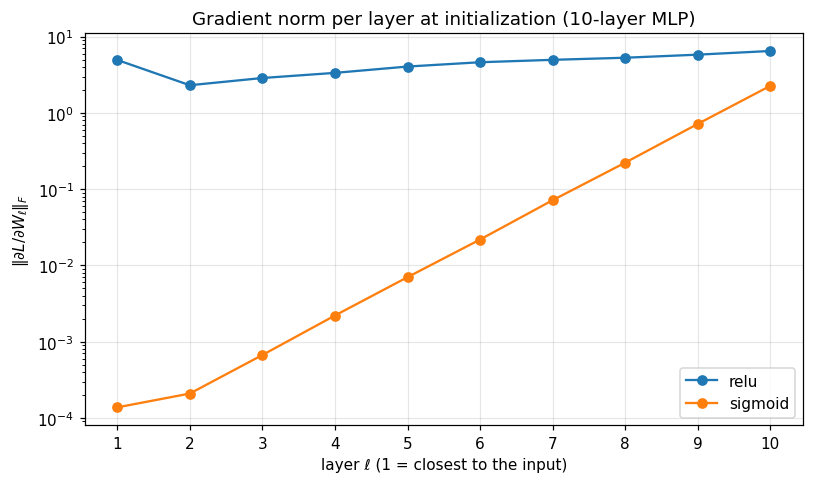

,relu,sigmoid
layer,,
1,4.95e+00,1.37e-04
2,2.31e+00,2.09e-04
3,2.87e+00,6.68e-04
4,3.35e+00,2.20e-03
5,4.05e+00,7.01e-03
6,4.61e+00,2.18e-02
7,4.96e+00,7.16e-02
8,5.29e+00,2.23e-01
9,5.80e+00,7.17e-01


   relu: gradient norm of layer 10 / layer 1 = 1.31
sigmoid: gradient norm of layer 10 / layer 1 = 1.65e+04


In [ ]:
xb, yb = next(train_set.batches(512))       # One batch of 512 training images
xb = xb.flatten(1)                          # Images -> vectors of 3072 values
depth_sizes = [3072] + [256] * 9 + [10]     # 10 Linear layers

grad_norms = {}
for activation in ['relu', 'sigmoid']:
    runs = []
    for seed in range(5):                   # 5 random initializations
        net = MLP(depth_sizes, activation=activation, seed=seed)
        net.loss(xb, yb)
        net.backward()
        # ||dL/dW|| per layer
        runs.append([layer.dW.norm().item() for layer in net.linears])
    grad_norms[activation] = np.mean(runs, axis=0)  # Average over the 5 initializations

# Plot the gradient norm per layer (log scale)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for activation, norms in grad_norms.items():
    ax.semilogy(range(1, 11), norms, marker='o', label=activation)
ax.set_xlabel('layer ℓ (1 = closest to the input)')
ax.set_ylabel(r'$\|\partial L/\partial W_\ell\|_F$')
ax.set_xticks(range(1, 11))
ax.set_title('Gradient norm per layer at initialization (10-layer MLP)')
ax.legend()
plt.tight_layout()
plt.show()

# Table of the same values
norm_table = pd.DataFrame(grad_norms, index=pd.RangeIndex(1, 11, name='layer'))
display(norm_table.style.format('{:.2e}'))
for activation, norms in grad_norms.items():
    ratio = norms[-1] / norms[0]
    print(f'{activation:>7}: gradient norm of layer 10 / layer 1 = {ratio:.3g}')

**Explanation:** In back-propagation, every layer multiplies the gradient by the derivative of its activation (downstream = local × upstream):

$$\delta_\ell = \phi'(z_\ell)\odot(W_{\ell+1}^\top\delta_{\ell+1}), \qquad \frac{\partial L}{\partial W_\ell}=\delta_\ell\, h_{\ell-1}^\top .$$

- **Sigmoid:** its derivative is at most 1/4, so the gradient gets smaller at every layer. It falls from 2.27 at layer 10 to $1.4\times10^{-4}$ at layer 1, about 16,500 times smaller (roughly 3× per layer). The first layers would hardly learn. This is the vanishing-gradient problem.
- **ReLU:** its derivative is 1 for active units, and Kaiming initialization ($\mathrm{Var}(W)=2/n_{\text{in}}$) makes up for the units that are off. The gradient norm stays between 2.3 and 6.5 in all ten layers, so every layer gets a useful learning signal.

---
## Task 2: Optimizers

### (a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses
Both optimizers use the standard update rules, written here for one weight tensor `w` with gradient `dw`.

**SGD + Momentum.** The velocity `v` is a running sum of past gradients:

- `v = rho * v + dw`, starting from `v = 0`
- `w -= learning_rate * v`

With `rho = 0` this is plain SGD. `torch.optim.SGD` with `momentum = rho` uses the same rule.

**Adam with bias correction.** Adam combines momentum (first moment) with a separate step size for every weight (second moment):

- `moment1 = beta1 * moment1 + (1 - beta1) * dw`
- `moment2 = beta2 * moment2 + (1 - beta2) * dw * dw`
- `moment1_unbias = moment1 / (1 - beta1 ** t)` and `moment2_unbias = moment2 / (1 - beta2 ** t)`. Both moments start at zero, so they are biased towards zero in the first steps. This correction removes that bias.
- `w -= learning_rate * moment1_unbias / (moment2_unbias.sqrt() + eps)`

The defaults are the same as PyTorch's: $\beta_1 = 0.9$, $\beta_2 = 0.999$ and $\epsilon = 10^{-8}$. The last line is computed in the same order as `torch.optim.Adam`, so the results match bit for bit.

In [ ]:
class MySGD(torch.optim.Optimizer):
    """SGD + Momentum: v = rho * v + dw, w -= learning_rate * v.
    momentum (rho) = 0 gives plain SGD. Same update rule as torch.optim.SGD."""

    def __init__(self, params, lr, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))  # Default settings

    # The update itself is not tracked by autograd
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:  # Optional: re-evaluate the loss (Optimizer API)
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, rho = group['lr'], group['momentum']
            for w in group['params']:
                if w.grad is None:
                    continue
                dw = w.grad
                if rho != 0:
                    state = self.state[w]  # Memory of the optimizer for this tensor
                    if 'v' not in state:
                        state['v'] = dw.clone()        # v = 0 at the start, so v = dw
                    else:
                        state['v'].mul_(rho).add_(dw)  # v = rho * v + dw
                    dw = state['v']
                w.add_(dw, alpha=-lr)                  # w -= learning_rate * v
        return loss

class MyAdam(torch.optim.Optimizer):
    """Adam with bias correction. Same update rule as torch.optim.Adam."""

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (beta1, beta2), eps = group['lr'], group['betas'], group['eps']
            for w in group['params']:
                if w.grad is None:
                    continue
                dw = w.grad
                state = self.state[w]
                if not state:                           # Both moments start at zero
                    state['t'] = 0
                    state['moment1'] = torch.zeros_like(w)
                    state['moment2'] = torch.zeros_like(w)
                state['t'] += 1                         # Step counter, starts at 1
                t, moment1, moment2 = state['t'], state['moment1'], state['moment2']
                # moment1 = beta1 * moment1 + (1 - beta1) * dw
                moment1.lerp_(dw, 1 - beta1)
                # moment2 = beta2 * moment2 + (1 - beta2) * dw * dw
                moment2.mul_(beta2).addcmul_(dw, dw, value=1 - beta2)
                bias1, bias2 = 1 - beta1 ** t, 1 - beta2 ** t   # Bias correction terms
                # w -= lr * moment1_unbias / (sqrt(moment2_unbias) + eps),
                # computed in PyTorch's order, with moment1_unbias = moment1 / bias1
                # and sqrt(moment2_unbias) = sqrt(moment2) / sqrt(bias2)
                denom = (moment2.sqrt() / math.sqrt(bias2)).add_(eps)
                w.addcdiv_(moment1, denom, value=-lr / bias1)
        return loss

**Check against PyTorch:** two copies of a small CNN start from the same weights. Both are trained for 100 steps on the same mini-batches, one with custom optimizer and one with PyTorch's, and their final parameters are compared with `torch.allclose`. This runs on the CPU, where every operation is deterministic.

In [ ]:
def tiny_cnn():
    return nn.Sequential(nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(16 * 8 * 8, 10))

def compare_optimizers(my_cls, torch_cls, kwargs, steps=100, batch_size=64):
    """Train two identical copies, one with each optimizer,
    and compare the final parameters."""
    torch.manual_seed(SEED)
    model_mine = tiny_cnn()
    # Exact copy: same starting weights
    model_torch = copy.deepcopy(model_mine)
    initial = [p.detach().clone() for p in model_mine.parameters()]
    opt_mine = my_cls(model_mine.parameters(), **kwargs)
    opt_torch = torch_cls(model_torch.parameters(), **kwargs)

    gen = torch.Generator(device=device)
    gen.manual_seed(SEED)
    # Endless stream of shuffled mini-batches
    def batch_stream():
        while True:
            yield from train_set.batches(batch_size, shuffle=True, gen=gen)
    batches = batch_stream()

    for _ in range(steps):
        xb, yb = next(batches)
        xb, yb = xb.cpu(), yb.cpu()                    # Run on the CPU (deterministic)
        # Same batch for both models
        for model, opt in ((model_mine, opt_mine), (model_torch, opt_torch)):
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            opt.step()

    mine = [p.detach() for p in model_mine.parameters()]
    ref = [p.detach() for p in model_torch.parameters()]
    # Largest difference between the two, and how far training moved the weights
    max_diff = max((a - b).abs().max().item() for a, b in zip(mine, ref))
    moved = max((a - p0).abs().max().item() for a, p0 in zip(mine, initial))
    match = all(torch.allclose(a, b, rtol=1e-5, atol=1e-6) for a, b in zip(mine, ref))
    return max_diff, moved, match

# (name, custom optimizer, PyTorch optimizer, settings)
cases = [('SGD',            MySGD,  torch.optim.SGD,  dict(lr=0.05)),
         ('SGD + momentum', MySGD,  torch.optim.SGD,  dict(lr=0.02, momentum=0.9)),
         ('Adam',           MyAdam, torch.optim.Adam, dict(lr=1e-3))]
rows = []
for name, my_cls, torch_cls, kwargs in cases:
    max_diff, moved, match = compare_optimizers(my_cls, torch_cls, kwargs)
    rows.append({'optimizer': name, 'hyper-parameters': str(kwargs),
                 'max |θ_ours − θ_torch|': f'{max_diff:.2e}',
                 'max |θ − θ_initial|': f'{moved:.2e}', 'torch.allclose': match})
display(pd.DataFrame(rows).style.hide(axis='index'))

optimizer,hyper-parameters,max |θ_ours − θ_torch|,max |θ − θ_initial|,torch.allclose
SGD,{'lr': 0.05},0.00e+00,1.12e-01,True
SGD + momentum,"{'lr': 0.02, 'momentum': 0.9}",0.00e+00,2.85e-01,True
Adam,{'lr': 0.001},0.00e+00,7.62e-02,True


**Interpretation:** For plain SGD, SGD with momentum and Adam, the largest difference from PyTorch is exactly 0, and `torch.allclose` passes. The weights moved by 0.08 to 0.29 during the 100 steps, so the models really trained and both optimizers followed the same path. The custom optimizers are therefore identical to `torch.optim.SGD` and `torch.optim.Adam`.

### (b) Trajectories of SGD, SGD + Momentum and Adam
The function is

$$f(x, y) = \frac{1}{2}\left(x^2 + 50y^2\right)$$

Its Hessian is $\mathrm{diag}(1, 50)$: the loss changes quickly in $y$ and slowly in $x$, so it has a high condition number (50). Each method starts at $(-10, 1)$ and takes 100 steps with the custom optimizers:

- SGD with $\eta=0.035$, just below the stability limit $2/50 = 0.04$
- SGD with momentum, $\eta=0.01$, $\rho=0.9$
- Adam with $\eta=0.5$

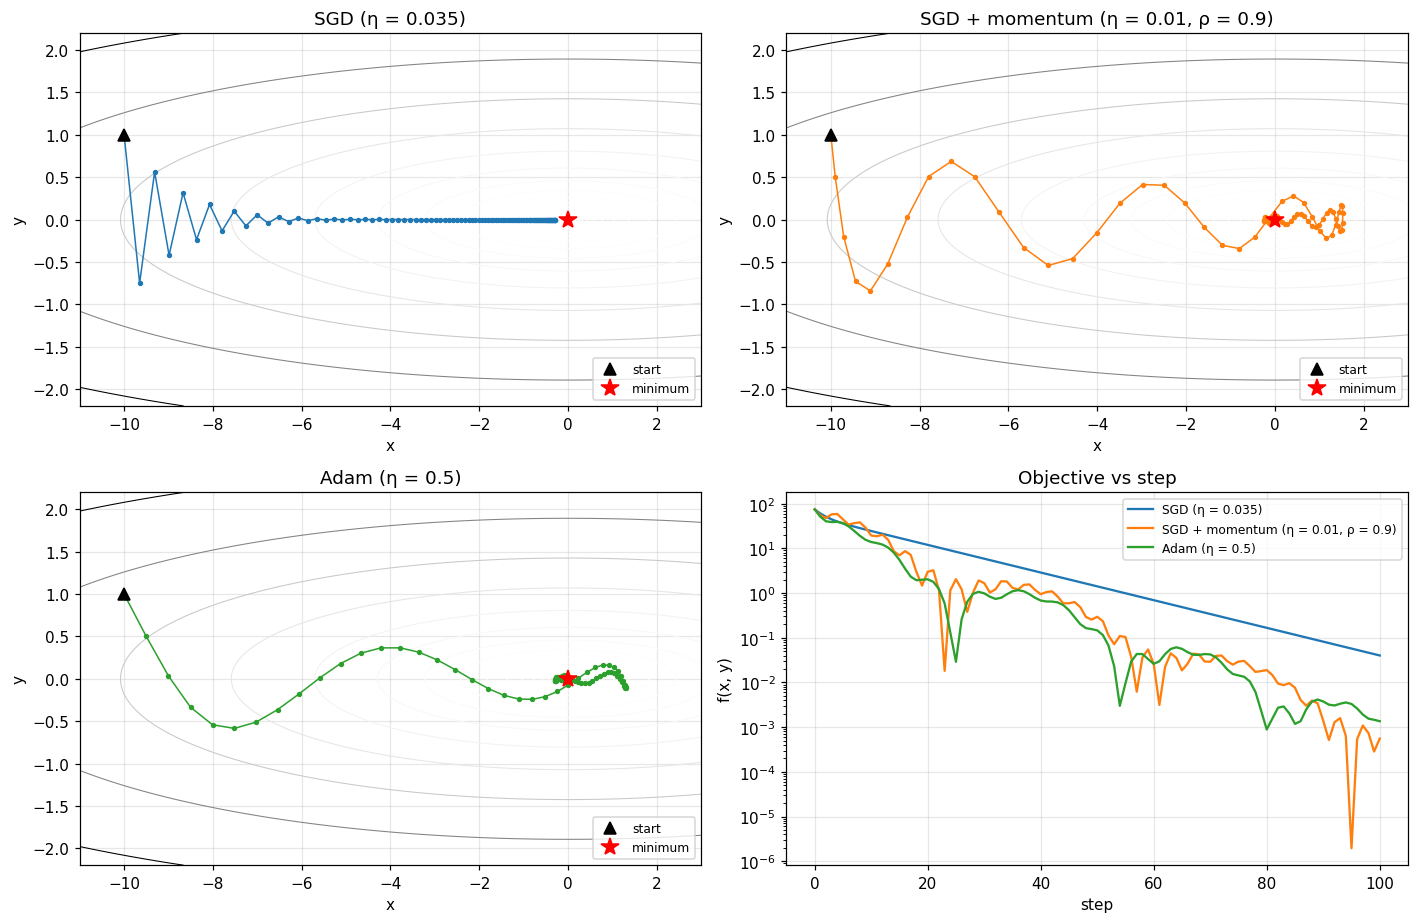

SGD (η = 0.035)                      final point (-0.2836,  0.0000) | f = 4.02e-02
SGD + momentum (η = 0.01, ρ = 0.9)   final point ( 0.0263,  0.0029) | f = 5.56e-04
Adam (η = 0.5)                       final point ( 0.0421, -0.0043) | f = 1.36e-03


In [ ]:
def f_quad(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)   # f(x, y) = (x^2 + 50 y^2) / 2

def trajectory(opt_cls, steps=100, start=(-10.0, 1.0), **kwargs):
    """Points visited by an optimizer minimizing f_quad from `start`."""
    # The point (x, y) being optimized
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_cls([p], **kwargs)
    path = [p.detach().clone()]
    for _ in range(steps):
        opt.zero_grad()
        f_quad(p).backward()                    # Gradient (x, 50 y)
        opt.step()
        path.append(p.detach().clone())         # Save every point for the plot
    return torch.stack(path).numpy()

paths = {'SGD (η = 0.035)': trajectory(MySGD, lr=0.035),
         'SGD + momentum (η = 0.01, ρ = 0.9)': trajectory(MySGD, lr=0.01, momentum=0.9),
         'Adam (η = 0.5)': trajectory(MyAdam, lr=0.5)}

# Contours of f on a grid, with each trajectory on top
xs, ys = np.meshgrid(np.linspace(-11, 3, 400), np.linspace(-2.2, 2.2, 400))
zs = 0.5 * (xs ** 2 + 50 * ys ** 2)
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, (name, path), color in zip(axes.flat[:3], paths.items(), ['C0', 'C1', 'C2']):
    ax.contour(xs, ys, zs, levels=np.logspace(-2, 2.2, 18), cmap='Greys',
               linewidths=0.7)
    ax.plot(path[:, 0], path[:, 1], 'o-', color=color, ms=2.5, lw=1)
    ax.plot(*path[0], 'k^', ms=8, label='start')
    ax.plot(0, 0, 'r*', ms=12, label='minimum')
    ax.set_title(name); ax.set_xlabel('x'); ax.set_ylabel('y')
    ax.legend(loc='lower right', fontsize=8)
# Objective value against the step number (log scale)
ax = axes[1, 1]
for (name, path), color in zip(paths.items(), ['C0', 'C1', 'C2']):
    ax.semilogy([f_quad(p) for p in path], color=color, label=name)
ax.set_xlabel('step'); ax.set_ylabel('f(x, y)'); ax.set_title('Objective vs step')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for name, path in paths.items():
    print(f'{name:36s} final point ({path[-1, 0]: .4f}, {path[-1, 1]: .4f}) '
          f'| f = {f_quad(path[-1]):.2e}')

**Explanation:**

- **SGD** zig-zags across the valley and moves slowly along it. The steep $y$ direction limits the step size: with $\eta = 0.035$, $y$ is multiplied by $1 - 50\eta = -0.75$ at each step, so it flips sign every step. In the flat $x$ direction the steps are tiny, because $x$ shrinks by only 3.5% per step. After 100 steps SGD is still at $x = -0.28$ ($f = 4.0\times10^{-2}$).
- **SGD + Momentum** keeps a velocity. Along $x$ the gradients always point the same way, so the velocity builds up and the effective step becomes about $\eta/(1-\rho) = 10\eta$. It moves along the valley much faster, overshoots the minimum and swings around it like a rolling ball. It ends at $f = 5.6\times10^{-4}$, about 70 times lower than SGD.
- **Adam** scales each coordinate by the size of its own recent gradients. Steps in the steep direction are damped and steps in the flat direction are boosted, so it moves about $\eta$ in both $x$ and $y$. It first moves diagonally, then straight along the valley. With a constant learning rate it keeps circling the minimum instead of settling, and ends at $f = 1.4\times10^{-3}$.

### (c) Small CNN with each optimizer at three learning rates
**Model:** conv(32) → conv(32) → pool → conv(64) → conv(64) → pool → conv(128) → pool → linear, about 160k parameters. There is no batch norm, so the choice of optimizer matters more.

**Training:** each of the three custom optimizers trains for 15 epochs with a constant learning rate, batch size 128 and no augmentation.

**Learning rates:** each optimizer gets three values around its usual range:

- Momentum's effective step is $\eta/(1-\rho)=10\eta$, so its values are lower than SGD's.
- Adam's step size does not depend on the size of the gradient, so it needs its own values. They include 1e-3 and 1e-4, common starting points for Adam, plus 1e-2 as a value that is too large.

In [ ]:
def small_cnn(bn=False, dropout=0.0):
    """Small CNN used in Tasks 2(c) and 3(a).
    bn: batch norm after each conv, dropout: after each pooling."""
    def conv_block(c_in, c_out):
        # No bias needed when BN follows
        layers = [nn.Conv2d(c_in, c_out, 3, padding=1, bias=not bn)]
        if bn:
            layers.append(nn.BatchNorm2d(c_out))
        layers.append(nn.ReLU(inplace=True))
        return layers

    def pool():
        return [nn.MaxPool2d(2)] + ([nn.Dropout(dropout)] if dropout > 0 else [])

    return nn.Sequential(
        *conv_block(3, 32), *conv_block(32, 32), *pool(),    # 32x32 -> 16x16
        *conv_block(32, 64), *conv_block(64, 64), *pool(),   # 16x16 -> 8x8
        *conv_block(64, 128), *pool(),                       # 8x8 -> 4x4
        nn.Flatten(), nn.Linear(128 * 4 * 4, 10))

print('small CNN parameters:', f'{count_params(small_cnn()):,}')

# Optimizer name -> (how to create it, its three learning rates)
OPT_GRID = {
    'SGD':            (lambda params, lr: MySGD(params, lr=lr), [0.01, 0.05, 0.2]),
    'SGD + momentum': (lambda params, lr: MySGD(params, lr=lr, momentum=0.9),
                       [0.001, 0.01, 0.05]),
    'Adam':           (lambda params, lr: MyAdam(params, lr=lr), [1e-4, 1e-3, 1e-2]),
}

def run_optimizer(make_opt, lr, name):
    set_seed()                                  # Same initial weights for every run
    model = small_cnn().to(device)
    return train_model(model, make_opt(model.parameters(), lr), train_set, val_set,
                       n_epochs(15), name=name)

t2c = {}
for opt_name, (make_opt, lrs) in OPT_GRID.items():
    for lr in lrs:
        file_name = f't2c_{opt_name.replace(" + ", "_").replace(" ", "")}_lr{lr}'
        run = lambda m=make_opt, lr=lr, n=opt_name: run_optimizer(m, lr, f'{n} lr={lr}')
        t2c[(opt_name, lr)] = cached(file_name, run)

small CNN parameters: 159,914
[t2c_SGD_lr0.01] loaded saved result
[t2c_SGD_lr0.05] loaded saved result
[t2c_SGD_lr0.2] loaded saved result
[t2c_SGD_momentum_lr0.001] loaded saved result
[t2c_SGD_momentum_lr0.01] loaded saved result
[t2c_SGD_momentum_lr0.05] loaded saved result
[t2c_Adam_lr0.0001] loaded saved result
[t2c_Adam_lr0.001] loaded saved result
[t2c_Adam_lr0.01] loaded saved result


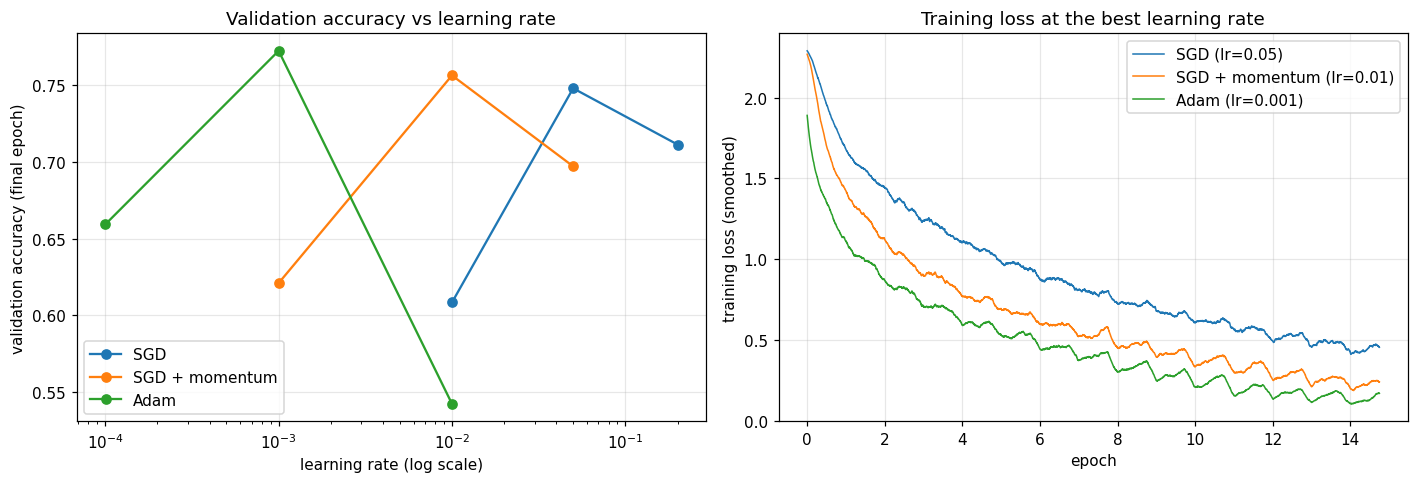

optimizer,learning rate,final val acc,best val acc,final train loss,diverged
SGD,0.010000,0.6084,0.6084,1.0874,False
SGD,0.050000,0.7478,0.7478,0.4395,False
SGD,0.200000,0.7112,0.7230,0.3353,False
SGD + momentum,0.001000,0.6210,0.6210,1.0512,False
SGD + momentum,0.010000,0.7562,0.7682,0.2212,False
SGD + momentum,0.050000,0.6970,0.7234,0.6676,False
Adam,0.000100,0.6592,0.6592,0.9136,False
Adam,0.001000,0.7722,0.7820,0.1302,False
Adam,0.010000,0.5424,0.5548,1.2677,False


SGD             best lr 0.05   | val acc range: 0.6084 - 0.7478
SGD + momentum  best lr 0.01   | val acc range: 0.6210 - 0.7562
Adam            best lr 0.001  | val acc range: 0.5424 - 0.7722


In [ ]:
summary, best_lr = [], {}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for i, (opt_name, (_, lrs)) in enumerate(OPT_GRID.items()):
    # Validation accuracy after the last epoch
    accs = [t2c[(opt_name, lr)]['val_acc'][-1] for lr in lrs]
    best_lr[opt_name] = lrs[int(np.argmax(accs))]
    for lr, acc in zip(lrs, accs):
        h = t2c[(opt_name, lr)]
        summary.append({'optimizer': opt_name, 'learning rate': lr,
                        'final val acc': acc,
                        'best val acc': max(h['val_acc']),
                        'final train loss': h['train_loss'][-1],
                        'diverged': h.get('diverged', False)})

    # Left: validation accuracy vs learning rate
    ax1.semilogx(lrs, accs, 'o-', color=f'C{i}', label=opt_name)
    # Right: training loss at the best learning rate (smoothed over a quarter epoch)
    h = t2c[(opt_name, best_lr[opt_name])]
    iter_loss = np.array(h['iter_loss'])
    iters_per_epoch = len(iter_loss) / len(h['train_loss'])
    k = max(1, int(iters_per_epoch // 4))
    smooth = np.convolve(iter_loss, np.ones(k) / k, mode='valid')  # Moving average
    ax2.plot(np.arange(len(smooth)) / iters_per_epoch, smooth, color=f'C{i}', lw=1,
             label=f'{opt_name} (lr={best_lr[opt_name]})')

ax1.set_xlabel('learning rate (log scale)')
ax1.set_ylabel('validation accuracy (final epoch)')
ax1.set_title('Validation accuracy vs learning rate'); ax1.legend()
ax2.set_xlabel('epoch'); ax2.set_ylabel('training loss (smoothed)')
ax2.set_title('Training loss at the best learning rate'); ax2.legend()
plt.tight_layout()
plt.show()

# Table of all nine runs
t2c_table = pd.DataFrame(summary)
display(t2c_table.style.format({'final val acc': '{:.4f}', 'best val acc': '{:.4f}',
                                'final train loss': '{:.4f}'}).hide(axis='index'))
for opt_name in OPT_GRID:
    accs = t2c_table[t2c_table.optimizer == opt_name]['final val acc']
    print(f'{opt_name:15s} best lr {best_lr[opt_name]:<6} '
          f'| val acc range: {accs.min():.4f} - {accs.max():.4f}')

**Discussion (sensitivity):**

- **Every optimizer works best in the middle of its range.** A learning rate that is too small trains too slowly: after 15 epochs SGD reaches 60.8%, momentum 62.1% and Adam 65.9%. One that is too large makes training unstable. No run diverged.
- **Adam** gives the best accuracy, 77.2% at lr = 1e-3, and the lowest training loss (0.13). It is also the most sensitive to a large learning rate: at 1e-2 it drops to 54.2%, and its training loss stays at 1.27.
- **SGD + momentum** reaches 75.6% at lr = 0.01. Its best rate is 5 times lower than plain SGD's (0.05, 74.8%), because momentum makes the effective step about 10 times larger.
- **Training loss (right plot):** Adam and momentum lower the training loss much faster than plain SGD. At their best rates they start to overfit, so their final validation accuracy is slightly below their best.
- **Overall:** Adam with lr = 1e-3 works well without much tuning. SGD with momentum comes close (1.6 points lower), but only with the right learning rate.

---
## Task 3: Regularization and residual connections

### (a) Regularization on 5k training images
**Model:** the small CNN from Task 2 with batch norm after every conv. It is trained on only **5,000** training images, so it overfits.

**Regularization:** the loss becomes $L(W) = \frac{1}{N}\sum_i L_i + \lambda R(W)$. With L2 regularization, $R(W) = \sum W^2$. For SGD with momentum this is the same as weight decay. PyTorch's `weight_decay = 5e-4` adds $5\cdot10^{-4}\,W$ to the gradient, which corresponds to $\lambda = 2.5\cdot10^{-4}$.

**Training** (the same for every run): 80 epochs, batch size 128, SGD with momentum 0.9. The learning rate is 0.05, with a 3-epoch warm-up and then cosine decay. The warm-up stops the loss from blowing up in the first steps.

| config | change |
|---|---|
| baseline | none |
| weight decay | L2 penalty 5e-4 |
| dropout | `Dropout(0.3)` after each pooling layer |
| flip + crop | random flip, then 4-pixel pad and random crop |
| cutout | one 16×16 square per image (own implementation) |
| mixup | α = 0.4 (own implementation) |
| all | all of the above together |

- **Train accuracy** is measured on the clean 5k training images in eval mode, without augmentation, mixup or dropout, so it means the same thing for every config.
- **Gap** = train accuracy − validation accuracy.

In [ ]:
# Fixed random 5k subset of the training split
train_5k = train_set.subset(5000)
REG_CONFIGS = {
    'baseline':     dict(),
    'weight decay': dict(weight_decay=5e-4),
    'dropout':      dict(dropout=0.3),
    'flip + crop':  dict(flip_crop=True),
    'cutout':       dict(cutout=16),
    'mixup':        dict(mixup_alpha=0.4),
    'all':          dict(weight_decay=5e-4, dropout=0.3, flip_crop=True, cutout=16,
                         mixup_alpha=0.4),
}

def run_regularization(cfg, name, epochs, lr=0.05, batch_size=128):
    set_seed()                                 # Same initial weights for every config
    model = small_cnn(bn=True, dropout=cfg.get('dropout', 0.0)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9,
                          weight_decay=cfg.get('weight_decay', 0.0))
    spe = steps_per_epoch(train_5k, batch_size)
    # 3-epoch warm-up, then cosine decay
    sched = warmup_cosine(opt, epochs * spe, warmup_steps=min(3, epochs) * spe)
    return train_model(model, opt, train_5k, val_set, epochs, scheduler=sched,
                       batch_size=batch_size,
                       augment=make_augment(cfg.get('flip_crop', False),
                                            cfg.get('cutout', 0)),
                       mixup_alpha=cfg.get('mixup_alpha', 0.0), train_eval=train_5k,
                       name=name, log_every=20)

t3a = {}
for name, cfg in REG_CONFIGS.items():
    file_name = 't3a_' + name.replace(' + ', '_').replace(' ', '_')
    run = lambda cfg=cfg, name=name: run_regularization(cfg, name, n_epochs(80))
    t3a[name] = cached(file_name, run)

[t3a_baseline] loaded saved result
[t3a_weight_decay] loaded saved result
[t3a_dropout] loaded saved result
[t3a_flip_crop] loaded saved result
[t3a_cutout] loaded saved result
[t3a_mixup] loaded saved result
[t3a_all] loaded saved result


,train acc,val acc,gap (train − val),best val acc,final val loss
config,,,,,
baseline,1.0000,0.6754,0.3246,0.6822,1.6400
weight decay,1.0000,0.6844,0.3156,0.6886,1.3326
dropout,0.9992,0.7096,0.2896,0.7128,1.0096
flip + crop,0.9682,0.7602,0.2080,0.7632,0.8043
cutout,1.0000,0.6996,0.3004,0.7024,1.4565
mixup,1.0000,0.6556,0.3444,0.6662,1.0614
all,0.7418,0.6808,0.0610,0.6848,0.9070


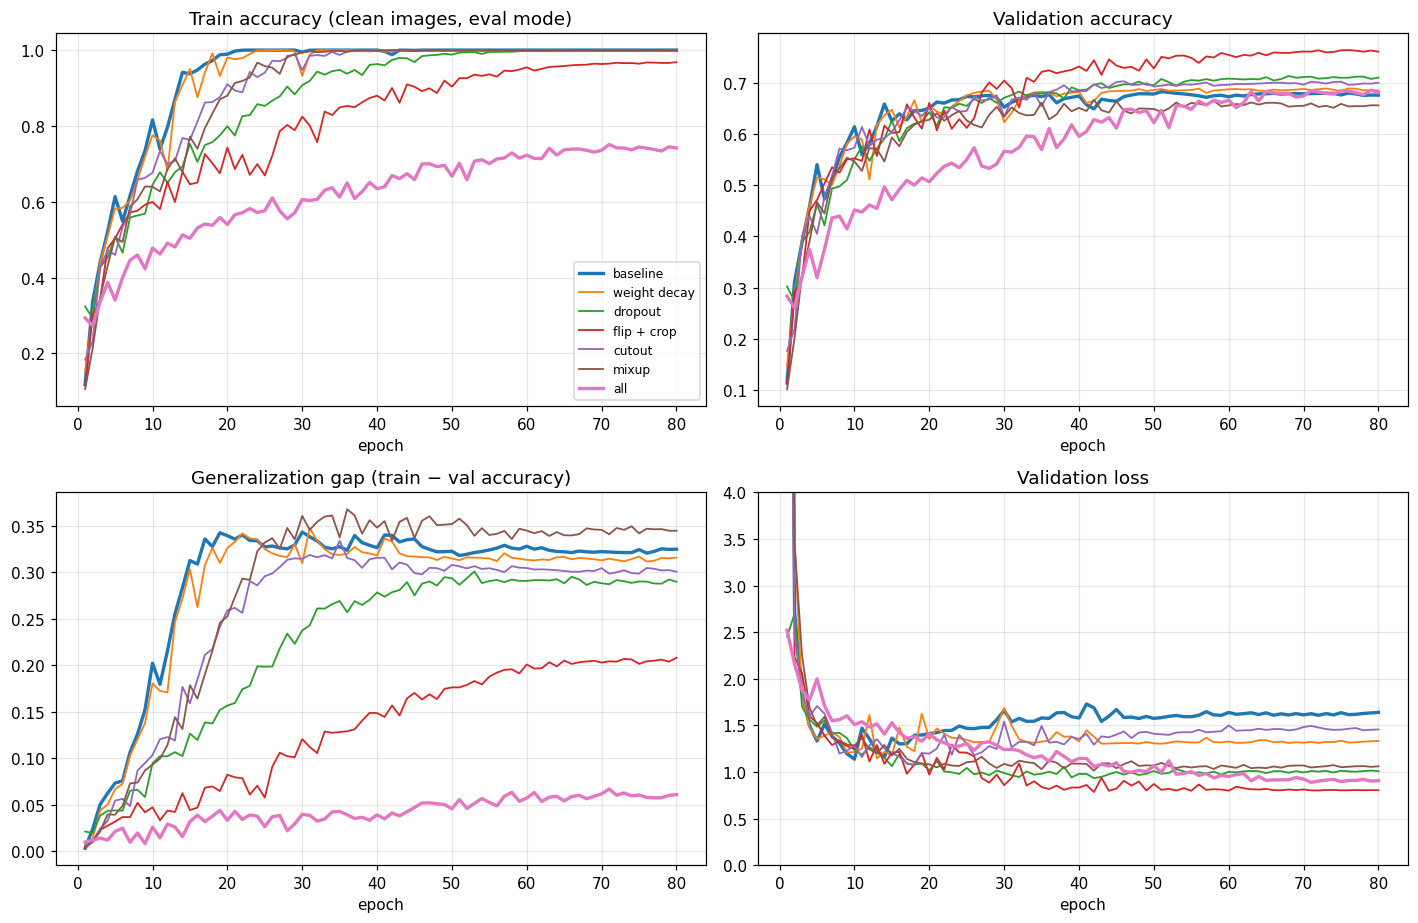

largest gap: mixup | smallest gap: all | highest val acc: flip + crop


In [ ]:
# Table (values after the last epoch)
rows = []
for name, h in t3a.items():
    train_acc, val_acc = h['train_eval_acc'][-1], h['val_acc'][-1]
    rows.append({'config': name, 'train acc': train_acc, 'val acc': val_acc,
                 'gap (train − val)': train_acc - val_acc,
                 'best val acc': max(h['val_acc']),
                 'final val loss': h['val_loss'][-1]})
t3a_table = pd.DataFrame(rows).set_index('config')
display(t3a_table.style.format('{:.4f}'))

# Curves of every config
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for i, (name, h) in enumerate(t3a.items()):
    ep = np.arange(1, len(h['val_acc']) + 1)
    lw = 2.2 if name in ('baseline', 'all') else 1.2  # Thicker for baseline / all
    style = dict(color=f'C{i}', lw=lw, label=name)
    axes[0, 0].plot(ep, h['train_eval_acc'], **style)
    axes[0, 1].plot(ep, h['val_acc'], **style)
    axes[1, 0].plot(ep, np.array(h['train_eval_acc']) - np.array(h['val_acc']), **style)
    axes[1, 1].plot(ep, h['val_loss'], **style)
titles = ['Train accuracy (clean images, eval mode)', 'Validation accuracy',
          'Generalization gap (train − val accuracy)', 'Validation loss']
for ax, title in zip(axes.flat, titles):
    ax.set_title(title); ax.set_xlabel('epoch')
axes[1, 1].set_ylim(0, min(4.0, 1.05 * max(max(h['val_loss']) for h in t3a.values())))
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

gap = t3a_table['gap (train − val)']
print('largest gap:', gap.idxmax(), '| smallest gap:', gap.idxmin(),
      '| highest val acc:', t3a_table['val acc'].idxmax())

**Discussion:** The baseline memorizes the 5k training images: 100% train accuracy but only 67.5% validation accuracy, a gap of 32.5%. This is strong overfitting. Its validation loss rises to 1.64 because it becomes over-confident on the images it gets wrong.

- **Flip + crop** works best: 76.0% validation accuracy, and the gap drops to 20.8%. It creates new, realistic versions of each image, so the network cannot simply memorize them.
- **Dropout** (71.0%) and **cutout** (70.0%) help a little.
- **Weight decay** changes very little (68.4%). With batch norm, it mainly changes the effective learning rate.
- **Mixup** (α = 0.4) did not help here. The network still memorized the clean training images, its validation accuracy (65.6%) is slightly below the baseline, and it has the largest gap (34.4%). Its only benefit is a lower validation loss (1.06 vs 1.64), so its predictions are less over-confident. With α = 0.4, λ is often close to 0 or 1, so many mixed images look almost like the originals.
- **All combined** has by far the smallest gap (6.1%), but its train accuracy is only 74.2%. The model now underfits: it cannot even fit the training set. Its validation accuracy (68.1%) is lower than flip + crop alone, so stacking every regularizer is too strong for this small model and 80 epochs.

### (b) Plain vs residual networks of depth 6n + 2
The networks have depths 8, 20 and 56 ($n = 1, 3, 9$) and follow the CIFAR ResNet of He et al. (2016):

- a 3×3 conv stem with 16 channels, then three stages of $n$ blocks with 16, 32 and 64 channels. The first block of stages 2 and 3 halves the resolution with a stride-2 conv and doubles the channels.
- each block: conv3×3 → BN → ReLU → conv3×3 → BN → (+ shortcut) → ReLU
- global average pooling and a single linear layer instead of large fully connected layers, with Kaiming initialization

**The only difference is the shortcut.** Residual blocks add their input to their output. Where the shape changes, the shortcut subsamples and zero-pads the channels, which needs no parameters. Both families therefore have exactly the same layers and the same number of parameters.

**Training**, the same for all six networks: 30 epochs, batch size 128, flip + crop, SGD with momentum 0.9 and weight decay 5e-4. The learning rate is 0.1, with a 1-epoch warm-up and then cosine decay.

In [ ]:
class Block(nn.Module):
    """Basic block: conv-BN-ReLU-conv-BN (+ shortcut) -> ReLU.
    residual=False gives the plain block."""

    def __init__(self, c_in, c_out, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.residual = residual
        # The shortcut must change shape at the start of a stage
        self.reshape = stride != 1 or c_in != c_out
        self.extra_channels = c_out - c_in

    def shortcut(self, x):
        """Identity. Where the shape changes: subsample by 2 and
        zero-pad the new channels (no parameters)."""
        if self.reshape:
            # Halve the height and width
            x = x[:, :, ::2, ::2]
            pad = self.extra_channels
            x = F.pad(x, (0, 0, 0, 0, pad // 2, pad - pad // 2))  # Add zero channels
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            # The only difference between plain and residual
            out = out + self.shortcut(x)
        return F.relu(out)

class CifarNet(nn.Module):
    """CIFAR-style network of depth 6n + 2 (plain or residual)."""

    def __init__(self, depth, residual, num_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0, 'depth must be 6n + 2'
        n = (depth - 2) // 6                           # Blocks per stage
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        blocks, c_in = [], 16
        for c_out, stride in [(16, 1), (32, 2), (64, 2)]:            # The three stages
            for i in range(n):
                blocks.append(Block(c_in, c_out, stride if i == 0 else 1, residual))
                c_in = c_out
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, num_classes)

        # Kaiming initialization
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        # Global average pooling
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(x)

for depth in (8, 20, 56):
    n_plain = count_params(CifarNet(depth, False))
    n_res = count_params(CifarNet(depth, True))
    print(f'depth {depth:2d}: plain {n_plain:,} parameters | '
          f'residual {n_res:,} parameters')

depth  8: plain 75,290 parameters | residual 75,290 parameters
depth 20: plain 269,722 parameters | residual 269,722 parameters
depth 56: plain 853,018 parameters | residual 853,018 parameters


In [ ]:
DEPTHS = (8, 20, 56)

def run_depth(depth, residual, epochs, lr=0.1, batch_size=128):
    # Same initial weights for plain and residual
    set_seed()
    model = CifarNet(depth, residual).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    spe = steps_per_epoch(train_set, batch_size)
    # 1-epoch warm-up, then cosine
    sched = warmup_cosine(opt, epochs * spe, warmup_steps=spe)
    name = f"{'resnet' if residual else 'plain'}-{depth}"
    return train_model(model, opt, train_set, val_set, epochs, scheduler=sched,
                       batch_size=batch_size, augment=make_augment(flip_crop=True),
                       name=name, log_every=5)

t3b = {}
for residual in (False, True):
    for depth in DEPTHS:
        key = f"{'resnet' if residual else 'plain'}-{depth}"
        run = lambda d=depth, r=residual: run_depth(d, r, n_epochs(30))
        t3b[key] = cached(f't3b_{key}', run)

[t3b_plain-8] loaded saved result
[t3b_plain-20] loaded saved result
[t3b_plain-56] loaded saved result
[t3b_resnet-8] loaded saved result
[t3b_resnet-20] loaded saved result
[t3b_resnet-56] loaded saved result


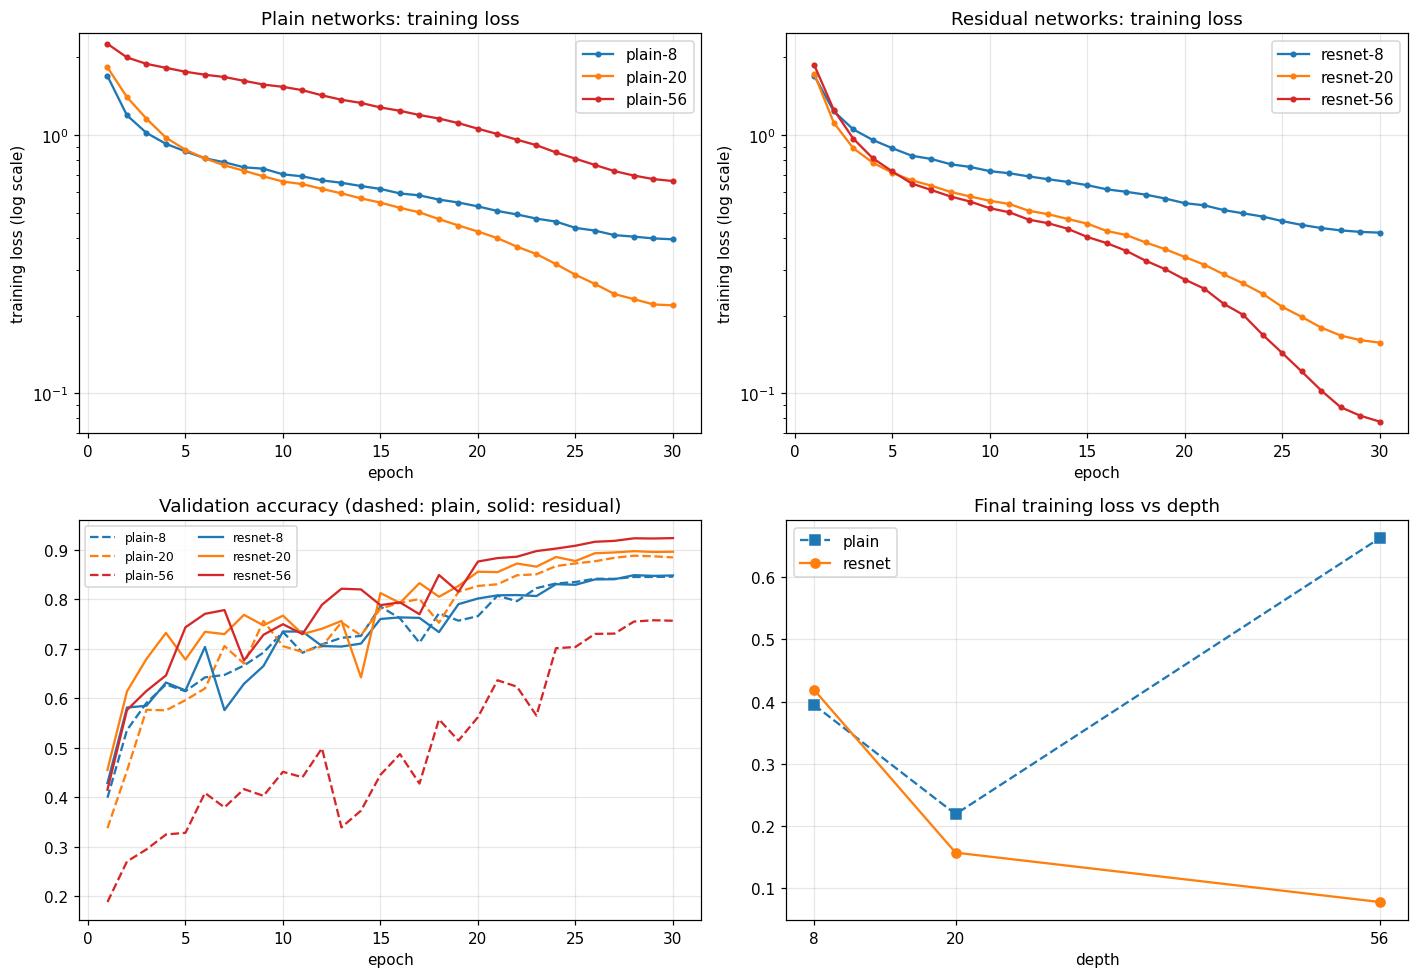

depth,network,parameters,final train loss,final val acc,training time (min)
8,plain,"75,290",0.3945,0.8460,1.2
8,resnet,"75,290",0.4186,0.8484,1.3
20,plain,"269,722",0.2190,0.8850,2.7
20,resnet,"269,722",0.1571,0.8964,2.9
56,plain,"853,018",0.6629,0.7568,7.3
56,resnet,"853,018",0.0778,0.9240,7.6


In [ ]:
colors = dict(zip(DEPTHS, ['C0', 'C1', 'C3']))
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Top: training loss vs epoch, plain (left) and residual (right), on the same y-axis
for ax, family in zip(axes[0], ['plain', 'resnet']):
    for d in DEPTHS:
        h = t3b[f'{family}-{d}']
        ax.plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', ms=3,
                color=colors[d], label=f'{family}-{d}')
    family_name = 'Plain' if family == 'plain' else 'Residual'
    ax.set_title(f'{family_name} networks: training loss')
    ax.set_xlabel('epoch'); ax.set_ylabel('training loss (log scale)')
    ax.set_yscale('log'); ax.legend()
y_min = min(min(h['train_loss']) for h in t3b.values())
y_max = max(max(h['train_loss']) for h in t3b.values())
for ax in axes[0]:
    ax.set_ylim(y_min * 0.9, y_max * 1.1)

# Bottom left: validation accuracy of all six networks
for family, line in [('plain', '--'), ('resnet', '-')]:
    for d in DEPTHS:
        h = t3b[f'{family}-{d}']
        axes[1, 0].plot(range(1, len(h['val_acc']) + 1), h['val_acc'], line,
                        color=colors[d], label=f'{family}-{d}')
axes[1, 0].set_title('Validation accuracy (dashed: plain, solid: residual)')
axes[1, 0].set_xlabel('epoch'); axes[1, 0].legend(fontsize=8, ncol=2)

# Bottom right: final training loss vs depth
for family, marker in [('plain', 's--'), ('resnet', 'o-')]:
    final_losses = [t3b[f'{family}-{d}']['train_loss'][-1] for d in DEPTHS]
    axes[1, 1].plot(DEPTHS, final_losses, marker, label=family)
axes[1, 1].set_xticks(DEPTHS)
axes[1, 1].set_title('Final training loss vs depth')
axes[1, 1].set_xlabel('depth'); axes[1, 1].legend()
plt.tight_layout()
plt.show()

# Table of the six networks
rows = []
for d in DEPTHS:
    for family in ('plain', 'resnet'):
        h = t3b[f'{family}-{d}']
        rows.append({'depth': d, 'network': family,
                     'parameters': count_params(CifarNet(d, family == 'resnet')),
                     'final train loss': h['train_loss'][-1],
                     'final val acc': h['val_acc'][-1],
                     'training time (min)': h['time'] / 60})
fmt = {'parameters': '{:,}', 'final train loss': '{:.4f}', 'final val acc': '{:.4f}',
       'training time (min)': '{:.1f}'}
display(pd.DataFrame(rows).style.format(fmt).hide(axis='index'))

**Explanation:** These are training losses, so they show how easy each network is to optimize. They are not about overfitting.

- **Plain networks get worse when they are too deep.** Plain-20 reaches a lower training loss than plain-8 (0.219 vs 0.395), but plain-56 ends much higher (0.663) and has the lowest validation accuracy (75.7%). Plain-56 is worse on the training set too, so this is underfitting, not overfitting. A 56-layer network could copy the 20-layer one and set its extra layers to the identity, but training does not find that solution. Very deep plain networks are simply hard to optimize.
- **Residual networks get better with depth.** The training loss falls from 0.419 (depth 8) to 0.157 (20) to 0.078 (56), and validation accuracy rises from 84.8% to 89.6% to 92.4%. In a residual block $x_{\ell+1} = x_\ell + F(x_\ell)$. If the block's weights are zero, the block just passes its input through, so extra layers cannot make the network worse. The shortcut also gives the gradient a direct path back to the early layers.
- **At depth 8** both families are almost the same (0.395 vs 0.419), and the difference grows with depth. The two families have the same layers and the same number of parameters, so the shortcut alone is what makes depth useful.

---
## Task 4: CNN with at most 500k parameters and 20 epochs
**Design:** a small ResNet with 464k parameters, built from standard design rules:

- **VGG:** all convs are 3×3 with stride 1 and padding 1, all max-pools are 2×2 with stride 2, and the number of channels grows as the resolution falls (32 → 64 channels at 32×32, 128 channels at 16×16, then pooled down to 8×8 and 4×4).
- **ResNet:** residual blocks of two 3×3 convs with an identity shortcut. Every conv is followed by batch norm and ReLU.
- **GoogLeNet / ResNet:** global average pooling and a single linear layer instead of large fully connected layers. This keeps the parameter count under 500k.

conv(32) → conv(64) + max-pool → residual block(64) → conv(128) + max-pool → residual block(128) → max-pool → global average pool → linear

**Training:**

- 20 epochs, batch size 256
- SGD with Nesterov momentum 0.9 and weight decay 5e-4
- learning rate: warm-up over the first 25% of the steps, then cosine decay
- label smoothing 0.1
- flip + crop + cutout (8×8)

**Steps:**

1. Tune the peak learning rate on the validation split.
2. Ablation: remove one design choice at a time (residual connections, augmentation, weight decay).
3. Evaluate the final model once on the test set.

In [ ]:
def conv_bn(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
                         nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))

class Residual(nn.Module):
    """Two conv-BN-ReLU layers with an identity shortcut
    (or without it, if residual=False)."""

    def __init__(self, channels, residual=True):
        super().__init__()
        self.body = nn.Sequential(conv_bn(channels, channels),
                                  conv_bn(channels, channels))
        self.residual = residual

    def forward(self, x):
        return x + self.body(x) if self.residual else self.body(x)

def net4(residual=True, widths=(32, 64, 128)):
    c0, c1, c2 = widths
    return nn.Sequential(
        conv_bn(3, c0),                                            # 32x32
        conv_bn(c0, c1), nn.MaxPool2d(2), Residual(c1, residual),  # -> 16x16
        conv_bn(c1, c2), nn.MaxPool2d(2), Residual(c2, residual),  # -> 8x8
        nn.MaxPool2d(2), nn.AdaptiveAvgPool2d(1), nn.Flatten(),    # -> 4x4 -> 1x1
        nn.Linear(c2, 10))

n_params = count_params(net4())
print(f'Task 4 network: {n_params:,} parameters')
assert n_params <= 500_000                         # Assignment limit

BASE_CONFIG = dict(residual=True, flip_crop=True, cutout=8, weight_decay=5e-4,
                   label_smoothing=0.1, lr=0.1)
EPOCHS_T4, BATCH_T4 = n_epochs(20), 256           # At most 20 epochs

def train_net4(cfg, name):
    """Train the Task 4 network with the settings in cfg, or load the saved run.
    Returns (model, history)."""
    set_seed()
    model = net4(cfg['residual']).to(device)

    def train():
        opt = torch.optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9,
                              nesterov=True, weight_decay=cfg['weight_decay'])
        total_steps = EPOCHS_T4 * steps_per_epoch(train_set, BATCH_T4)
        # 25% warm-up, then cosine decay
        sched = warmup_cosine(opt, total_steps, warmup_steps=int(0.25 * total_steps))
        return train_model(model, opt, train_set, val_set, EPOCHS_T4, scheduler=sched,
                           batch_size=BATCH_T4,
                           augment=make_augment(cfg['flip_crop'], cfg['cutout']),
                           label_smoothing=cfg['label_smoothing'],
                           name=name, log_every=5)

    # Also saves / loads the trained weights
    hist = cached(f't4_{name}', train, model=model)
    return model, hist

Task 4 network: 464,170 parameters


### Tuning the peak learning rate on the validation split

In [ ]:
t4_lr = {lr: train_net4({**BASE_CONFIG, 'lr': lr}, f'lr{lr}')
         for lr in (0.05, 0.1, 0.2)}
# Highest final validation accuracy
best_lr4 = max(t4_lr, key=lambda lr: t4_lr[lr][1]['val_acc'][-1])
display(pd.DataFrame({'peak learning rate': list(t4_lr),
                      'final val acc': [h['val_acc'][-1] for _, h in t4_lr.values()]})
        .style.format({'final val acc': '{:.4f}'}).hide(axis='index'))
print('selected peak learning rate:', best_lr4)

[t4_lr0.05] loaded saved result
[t4_lr0.1] loaded saved result
[t4_lr0.2] loaded saved result


peak learning rate,final val acc
0.050000,0.8928
0.100000,0.9080
0.200000,0.9066


selected peak learning rate: 0.1


**Interpretation:** A peak learning rate of 0.1 gives the best validation accuracy (90.8%). A rate of 0.2 is almost as good (90.7%), and 0.05 is 1.5 points lower (89.3%). The model is therefore not very sensitive to the learning rate in this range.

### Ablation of design choices
Each row starts from the tuned model and removes exactly one design choice.

[t4_abl_no_residual] loaded saved result
[t4_abl_no_augmentation] loaded saved result
[t4_abl_no_weight_decay] loaded saved result


,val acc,change vs full model,final train loss
configuration,,,
full model,0.9080,+0.0000,0.7194
no residual,0.8998,-0.0082,0.7214
no augmentation,0.8820,-0.0260,0.5320
no weight decay,0.8950,-0.0130,0.7402


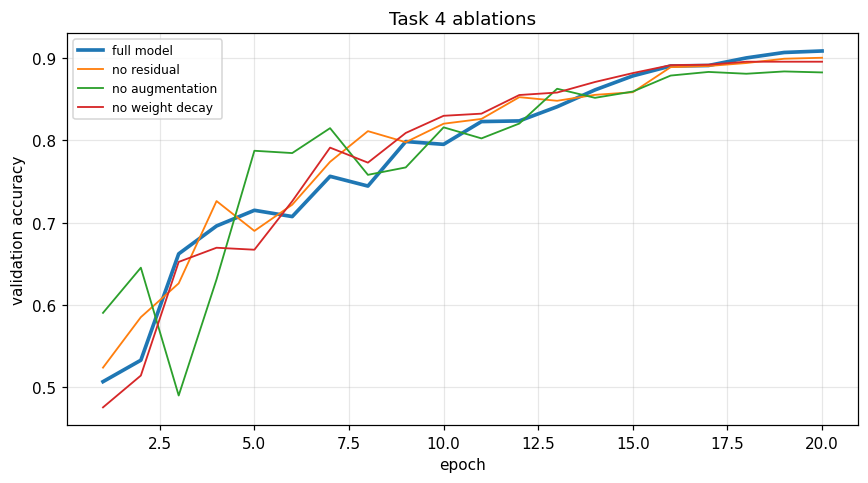

In [ ]:
FINAL_CONFIG = {**BASE_CONFIG, 'lr': best_lr4}     # Tuned settings
ABLATIONS = {
    'full model':          FINAL_CONFIG,
    'no residual': {**FINAL_CONFIG, 'residual': False},
    'no augmentation':     {**FINAL_CONFIG, 'flip_crop': False, 'cutout': 0},
    'no weight decay':     {**FINAL_CONFIG, 'weight_decay': 0.0},
}
t4_ablation = {}
for name, cfg in ABLATIONS.items():
    if name == 'full model':
        t4_ablation[name] = t4_lr[best_lr4]            # Already trained during tuning
    else:
        run_name = 'abl_' + name.split(' (')[0].replace(' ', '_')
        t4_ablation[name] = train_net4(cfg, run_name)

# Table: validation accuracy and change compared with the full model
full_acc = t4_ablation['full model'][1]['val_acc'][-1]
rows = [{'configuration': name, 'val acc': h['val_acc'][-1],
         'change vs full model': h['val_acc'][-1] - full_acc,
         'final train loss': h['train_loss'][-1]}
        for name, (_, h) in t4_ablation.items()]
ablation_table = pd.DataFrame(rows).set_index('configuration')
fmt = {'val acc': '{:.4f}', 'change vs full model': '{:+.4f}',
       'final train loss': '{:.4f}'}
display(ablation_table.style.format(fmt))

# Validation accuracy curves
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (name, (_, h)) in enumerate(t4_ablation.items()):
    ax.plot(range(1, len(h['val_acc']) + 1), h['val_acc'],
            lw=2.4 if name == 'full model' else 1.2, color=f'C{i}', label=name)
ax.set_xlabel('epoch'); ax.set_ylabel('validation accuracy')
ax.set_title('Task 4 ablations')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Discussion:** All three design choices help.

- **Augmentation** matters most. Without it, validation accuracy drops by 2.6 points to 88.2%. The training loss is lower (0.53 vs 0.72) while validation accuracy is worse, which is a clear sign of overfitting.
- **Weight decay:** without it, accuracy drops by 1.3 points to 89.5%. With batch norm, weight decay keeps the effective learning rate of the conv weights from shrinking.
- **Residual connections:** without them, accuracy drops by 0.8 points to 90.0%. The network has only 7 conv layers, so the effect is much smaller than for the 56-layer networks in Task 3(b).

The training losses stay above 0.5 because of label smoothing. Each result comes from a single run, so differences below about 0.5 points could be noise.

### Final test accuracy (evaluated once)
All hyperparameters were chosen on the validation set. The test set is used only here, once, at the end.

In [ ]:
final_model, final_hist = t4_ablation['full model']
# The only use of the test set
test_loss, test_acc = evaluate(final_model, test_set)
print(f'final model: {count_params(final_model):,} parameters, {EPOCHS_T4} epochs, '
      f'peak learning rate {best_lr4}')
print(f'validation accuracy: {final_hist["val_acc"][-1]:.4f}')
print(f'TEST accuracy:       {test_acc:.4f}   (test loss {test_loss:.4f})')

final model: 464,170 parameters, 20 epochs, peak learning rate 0.1
validation accuracy: 0.9080
TEST accuracy:       0.8992   (test loss 0.3528)


**Result:** The final model reaches **89.9% test accuracy** (test loss 0.353), with 464k parameters and 20 epochs of training. This is 0.9 points below its validation accuracy (90.8%). A small drop is expected: the learning rate was chosen with the validation set, so the validation score is slightly optimistic. The test accuracy is the fair estimate of how the model performs on new images.

---
## Conclusion

- **Backpropagation (Task 1):** The manual forward and backward passes match autograd to about $10^{-16}$ and finite differences to about $10^{-8}$ or better. The MLP reaches 51.2% validation accuracy at best and overfits quickly, because it ignores image structure. In a 10-layer MLP the sigmoid gradients vanish (about 16,500 times smaller at the first layer), while ReLU with Kaiming initialization keeps them at the same size in every layer.
- **Optimizers (Task 2):** The custom SGD with momentum and Adam give exactly the same results as PyTorch's. On the narrow valley $f(x, y)$, momentum and Adam get much closer to the minimum than plain SGD. On the small CNN, Adam does best (77.2%), followed by SGD with momentum (75.6%) and plain SGD (74.8%), and all three need a well-chosen learning rate.
- **Regularization (Task 3a):** With only 5k training images, flip + crop is the most useful regularizer (76.0% validation accuracy, gap down from 32.5% to 20.8%). Combining all regularizers removes almost all overfitting but makes the model underfit, so more regularization is not always better.
- **Residual connections (Task 3b):** Plain networks get harder to train as they get deeper: plain-56 is worse than plain-20 even on the training set. With shortcuts, deeper is better: ResNet-56 reaches the lowest training loss (0.078) and the best validation accuracy (92.4%).
- **CNN (Task 4):** A small ResNet with 464k parameters, trained for 20 epochs, reaches **89.9% test accuracy**. Data augmentation matters most (−2.6 points without it), followed by weight decay (−1.3) and residual connections (−0.8).

**Overall:** good results come from the right combination of a suitable architecture (residual connections), a well-tuned optimizer and learning rate, and data augmentation. All choices were made on the validation set, and the test set was used only once, at the end.

---
## Acknowledgement of AI tool use
I acknowledge that I used **Claude** as a coding assistant for this assignment. It helped write and test the code and draft the explanatory text. I ran the experiments on Google Colab and checked the code, the results and the interpretations against my own outputs.